In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory


# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
import os, re, glob
import xml.etree.ElementTree as ET
import pandas as pd

ROOT = "/kaggle/input/datasets/blanderbuss/parking-lot-dataset"

In [2]:

# find the folder that contains PUCPR/UFPR04/UFPR05
base = next(p for p in glob.glob(f"{ROOT}/**/PUCPR", recursive=True)
            if "Segmented" not in p)
base = os.path.dirname(base)
print("Using:", base)

rows = []
for xml_path in glob.glob(f"{base}/*/*/*/*.xml"):
    lot, weather, day, fname = xml_path.split(os.sep)[-4:]
    jpg = xml_path[:-4] + ".jpg"
    if not os.path.exists(jpg):
        continue
    try:
        spaces = ET.parse(xml_path).getroot().findall("space")
    except ET.ParseError:
        rows.append(dict(image_path=jpg, lot=lot, weather=weather, day=day, bad_xml=True))
        continue
    occ = sum(1 for s in spaces if s.get("occupied") == "1")
    rows.append(dict(image_path=jpg, lot=lot, weather=weather, day=day,
                     n_occupied=occ, n_spaces=len(spaces), bad_xml=False))

df = pd.DataFrame(rows)
df.to_csv("/kaggle/working/labels.csv", index=False)
print(df.groupby(["lot", "weather"]).agg(images=("image_path", "count"),
                                         days=("day", "nunique")))

Using: /kaggle/input/datasets/blanderbuss/parking-lot-dataset/PKLot/PKLot
                images  days
lot    weather              
PUCPR  Cloudy     1328    11
       Rainy       831     8
       Sunny      2314    24
UFPR04 Cloudy     1408    15
       Rainy       285    14
       Sunny      2098    20
UFPR05 Cloudy     1426    19
       Rainy       226     8
       Sunny      2500    25


In [3]:
pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.9/47.9 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 30.1 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 103.8/103.8 kB 5.6 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [4]:
!cd /kaggle/working && zip -r pklot_backup.zip det *.csv

  adding: det/ (stored 0%)
  adding: det/chunk_007500_img.csv (deflated 84%)
  adding: det/chunk_001500_det.csv (deflated 86%)
  adding: det/chunk_009500_img.csv (deflated 84%)
  adding: det/chunk_003500_img.csv (deflated 84%)
  adding: det/chunk_001000_img.csv (deflated 84%)
  adding: det/chunk_010000_det.csv (deflated 86%)
  adding: det/chunk_000000_img.csv (deflated 84%)
  adding: det/chunk_004500_det.csv (deflated 86%)
  adding: det/chunk_000500_det.csv (deflated 85%)
  adding: det/chunk_007000_det.csv (deflated 86%)
  adding: det/chunk_012000_img.csv (deflated 84%)
  adding: det/chunk_007500_det.csv (deflated 86%)
  adding: det/chunk_010500_img.csv (deflated 84%)
  adding: det/chunk_004000_det.csv (deflated 85%)
  adding: det/chunk_012000_det.csv (deflated 86%)
  adding: det/chunk_008000_img.csv (deflated 84%)
  adding: det/chunk_002000_det.csv (deflated 86%)
  adding: det/chunk_011500_img.csv (deflated 84%)
  adding: det/chunk_000000_det.csv (deflated 85%)
  adding: det/chunk_001

In [6]:
DATA = "/kaggle/input/<your-dataset-name>"      # check the exact name in the sidebar
# read: f"{DATA}/splits.csv", glob f"{DATA}/det/chunk_*_det.csv", etc.
# write results to /kaggle/working/ as before

In [7]:
import numpy as np
df = pd.read_csv("/kaggle/working/labels.csv")
df = df[~df.bad_xml].sort_values("image_path").reset_index(drop=True)
fn = df.image_path.str.extract(r"(\d{4}-\d{2}-\d{2})_(\d{2})_(\d{2})_(\d{2})")
df["date"] = pd.to_datetime(fn[0]); df["hour"] = fn[1].astype(int) + fn[2].astype(int) / 60
df["group"] = df.lot + "_" + df.day

HOLDOUT_LOT = "UFPR05"
rng = np.random.default_rng(42)
df["split"] = None
tl = df.lot != HOLDOUT_LOT
df.loc[~tl, "split"] = "test_newlot"
df.loc[tl & (df.weather == "Cloudy"), "split"] = "test_cloudy"
df.loc[tl & (df.weather == "Rainy"), "split"] = "test_rainy"
for lot in sorted(df.loc[tl, "lot"].unique()):
    m = (df.lot == lot) & (df.weather == "Sunny")
    days = np.sort(df.loc[m, "day"].unique())
    held = rng.choice(days, size=round(0.2 * len(days)), replace=False)
    df.loc[m & df.day.isin(held), "split"] = "test_sunny"
df.loc[tl & (df.weather == "Sunny") & df["split"].isna(), "split"] = "train"
df.to_csv("/kaggle/working/splits.csv", index=False)
print(df.groupby("split").agg(images=("image_path", "count"), days=("group", "nunique")))

             images  days
split                    
test_cloudy    2736    26
test_newlot    4152    33
test_rainy     1116    22
test_sunny      873     9
train          3539    35


import os, cv2, numpy as np, pandas as pd
from ultralytics import YOLO

df = pd.read_csv("/kaggle/working/splits.csv")   # or the path where you saved it
paths = df.image_path.tolist()
det, seg, obb = YOLO("yolo11n.pt"), YOLO("yolo11n-seg.pt"), YOLO("yolo11n-obb.pt")
ids = lambda m, want: [i for i, n in m.names.items() if n in want]
C = dict(det=ids(det, {"car","bus","truck"}), seg=ids(seg, {"car","bus","truck"}),
         obb=ids(obb, {"small vehicle","large vehicle"}))
print(C)   # check these look right
M = dict(det=det, seg=seg, obb=obb)
IMGSZ, CHUNK = 1280, 500
os.makedirs("/kaggle/working/det", exist_ok=True)

for start in range(0, len(paths), CHUNK):
    out = f"/kaggle/working/det/chunk_{start:06d}"
    if os.path.exists(out + "_det.csv"): continue          # resume after a crash
    dets, imgs = [], []
    for p in paths[start:start + CHUNK]:
        g = cv2.imread(p, 0)
        imgs.append((p, g.mean(), g.std()))
        for k, m in M.items():
            r = m(p, conf=0.05, imgsz=IMGSZ, classes=C[k], device=0, verbose=False)[0]
            H, W = r.orig_shape
            if k == "obb":
                b = r.obb
                vals = zip(b.conf.tolist(), (b.xywhr[:, 2] * b.xywhr[:, 3] / (H * W)).tolist(),
                           np.degrees(b.xywhr[:, 4].cpu().numpy()).tolist())
            else:
                b = r.boxes
                area = (b.xywh[:, 2] * b.xywh[:, 3] / (H * W)).tolist()
                mf = r.masks.data.float().mean((1, 2)).tolist() if (k == "seg" and r.masks is not None) else [np.nan] * len(area)                
                vals = zip(b.conf.tolist(), mf if k == "seg" else area, [np.nan] * len(area))
            dets += [(p, k, c, a, ang) for c, a, ang in vals]
    pd.DataFrame(dets, columns=["image_path","model","conf","area","angle"]).to_csv(out + "_det.csv", index=False)
    pd.DataFrame(imgs, columns=["image_path","brightness","contrast"]).to_csv(out + "_img.csv", index=False)
    print("done", start)

In [8]:
import glob, pandas as pd, numpy as np
D = pd.concat(pd.read_csv(f) for f in sorted(glob.glob("/kaggle/working/det/chunk_*_det.csv")))
I = pd.concat(pd.read_csv(f) for f in sorted(glob.glob("/kaggle/working/det/chunk_*_img.csv")))
df = pd.read_csv("/kaggle/working/splits.csv")

print(len(I), I.image_path.nunique(), len(df))          # all three should be 12416
print("missing:", len(set(df.image_path) - set(I.image_path)))
print(D.groupby("model").agg(rows=("conf","size"), imgs=("image_path","nunique")))
print(D[D.model=="seg"].area.isna().sum(), "seg rows with NaN area")

12416 12416 12416
missing: 0
         rows   imgs
model               
det    725021  11712
obb    306309   6113
seg    671982  11568
0 seg rows with NaN area


In [9]:
T = 0.25
paths = pd.Index(df.image_path)

def per_image(d, name, stat):                     # helper: aggregate, reindex to all images
    return stat(d.groupby("image_path")).reindex(paths)

F = pd.DataFrame(index=paths)
for k in ["det", "seg", "obb"]:
    d = D[(D.model == k) & (D.conf >= T)]
    F[f"n_{k}"] = d.groupby("image_path").size().reindex(paths).fillna(0)

d = D[(D.model == "det") & (D.conf >= T)].groupby("image_path")
F["conf_mean"], F["conf_std"], F["conf_min"] = [d.conf.agg(s).reindex(paths) for s in ["mean", "std", "min"]]
F["area_mean"], F["area_std"] = [d.area.agg(s).reindex(paths) for s in ["mean", "std"]]
F["area_total"] = d.area.sum().reindex(paths).fillna(0)
low = D[(D.model == "det") & D.conf.between(0.1, 0.4)]
F["n_low_conf"] = low.groupby("image_path").size().reindex(paths).fillna(0)

s = D[(D.model == "seg") & (D.conf >= T)]
F["mask_frac"] = s.groupby("image_path").area.sum().reindex(paths).fillna(0)
o = D[(D.model == "obb") & (D.conf >= T)]
F["angle_std"] = o.groupby("image_path").angle.std().reindex(paths)

F["d_det_seg"] = F.n_det - F.n_seg
F["d_det_obb"] = F.n_det - F.n_obb
F = F.join(I.set_index("image_path")[["brightness", "contrast"]])
F = F.fillna({c: 0 for c in ["conf_mean","conf_std","conf_min","area_mean","area_std","angle_std"]})

out = df.set_index("image_path")[["lot","weather","day","group","split","hour","n_occupied","n_spaces"]].join(F)
out["residual"] = out.n_occupied - out.n_det
out.reset_index().to_csv("/kaggle/working/features.csv", index=False)
print(out.groupby("split")[["n_occupied", "n_det"]].mean())

             n_occupied      n_det
split                             
test_cloudy   19.728070  14.473684
test_newlot   23.464836  37.894027
test_rainy    51.485663  20.269713
test_sunny    22.313860  24.194731
train         30.358011  29.111331


In [10]:
out = pd.read_csv("/kaggle/working/features.csv")
out["err"] = out.n_det - out.n_occupied
g = out.groupby(["split", "lot", "weather"])
print(g.agg(imgs=("err","size"), cap=("n_spaces","first"), true=("n_occupied","mean"),
            yolo=("n_det","mean"), bias=("err","mean"),
            mae=("err", lambda e: e.abs().mean())).round(1))
print(g.apply(lambda d: d.n_det.corr(d.n_occupied)).round(2).rename("corr"))

                            imgs  cap  true  yolo  bias   mae
split       lot    weather                                   
test_cloudy PUCPR  Cloudy   1328  100  31.9  10.9 -21.0  25.5
            UFPR04 Cloudy   1408   28   8.2  17.8   9.6   9.6
test_newlot UFPR05 Cloudy   1426   40  23.7  38.9  15.2  15.2
                   Rainy     226   40  26.9  45.7  18.8  18.9
                   Sunny    2500   40  23.0  36.6  13.6  13.7
test_rainy  PUCPR  Rainy     831  100  66.3  21.5 -44.8  48.9
            UFPR04 Rainy     285   28   8.3  16.5   8.3   8.3
test_sunny  PUCPR  Sunny     479  100  30.3  21.6  -8.8  20.7
            UFPR04 Sunny     394   28  12.6  27.4  14.8  14.9
train       PUCPR  Sunny    1835  100  43.7  24.2 -19.5  36.4
            UFPR04 Sunny    1704   28  16.0  34.4  18.4  18.4
split        lot     weather
test_cloudy  PUCPR   Cloudy     0.31
             UFPR04  Cloudy     0.98
test_newlot  UFPR05  Cloudy     0.98
                     Rainy      0.99
                 

/tmp/ipykernel_48/2204074979.py:7: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  print(g.apply(lambda d: d.n_det.corr(d.n_occupied)).round(2).rename("corr"))


In [11]:
import cv2, numpy as np, xml.etree.ElementTree as ET
from ultralytics import YOLO
det = YOLO("yolo11n.pt")

def polys(p):
    return [np.array([[int(pt.get("x")), int(pt.get("y"))] for pt in s.find("contour")], np.int32)
            for s in ET.parse(p[:-4] + ".xml").getroot().findall("space")]

def audit(p, save=None):
    P = polys(p)
    r = det(p, conf=0.25, imgsz=1280, classes=[2,5,7], device=0, verbose=False)[0]
    xy = r.boxes.xyxy.cpu().numpy()
    cs = (xy[:, :2] + xy[:, 2:]) / 2
    inside = [any(cv2.pointPolygonTest(q, (float(x), float(y)), False) >= 0 for q in P) for x, y in cs]
    if save:
        im = cv2.imread(p); cv2.polylines(im, P, True, (255, 0, 0), 1)
        for (x1, y1, x2, y2), ok in zip(xy, inside):
            cv2.rectangle(im, (int(x1), int(y1)), (int(x2), int(y2)), (0, 255, 0) if ok else (0, 0, 255), 2)
        cv2.imwrite(save, im)
    return len(inside), sum(inside)

for lot, w in [("UFPR05","Sunny"), ("UFPR04","Sunny"), ("PUCPR","Sunny"), ("PUCPR","Rainy")]:
    s = out[(out.lot == lot) & (out.weather == w)].sample(20, random_state=0)
    res = [audit(p, f"/kaggle/working/audit_{lot}_{w}_{i}.jpg" if i < 2 else None)
           for i, p in enumerate(s.image_path)]
    n, k = np.sum(res, 0)
    print(lot, w, f"{k}/{n} detections inside a marked space")
    

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
UFPR05 Sunny 349/582 detections inside a marked space
UFPR04 Sunny 316/666 detections inside a marked space
PUCPR Sunny 159/376 detections inside a marked space
PUCPR Rainy 226/357 detections inside a marked space


In [12]:
def audit2(p, save=None):
    im = cv2.imread(p); H, W = im.shape[:2]
    mask = np.zeros((H, W), np.uint8); cv2.fillPoly(mask, polys(p), 1)
    r = det(p, conf=0.25, imgsz=1280, classes=[2,5,7], device=0, verbose=False)[0]
    xy = r.boxes.xyxy.cpu().numpy().astype(int)
    frac = [mask[max(y1,0):y2, max(x1,0):x2].mean() if y2 > y1 and x2 > x1 else 0
            for x1, y1, x2, y2 in xy]
    ins = np.array(frac) >= 0.3
    if save:
        cv2.polylines(im, polys(p), True, (255, 0, 0), 1)
        for (x1, y1, x2, y2), ok in zip(xy, ins):
            cv2.rectangle(im, (x1, y1), (x2, y2), (0, 255, 0) if ok else (0, 0, 255), 2)
        cv2.imwrite(save, im)
    return len(ins), int(ins.sum())

for lot, w in [("UFPR05","Sunny"), ("UFPR04","Sunny"), ("PUCPR","Sunny"), ("PUCPR","Rainy")]:
    s = out[(out.lot == lot) & (out.weather == w)].sample(20, random_state=0)
    res = np.array([audit2(p, f"/kaggle/working/audit2_{lot}_{w}_{i}.jpg" if i < 2 else None)
                    for i, p in enumerate(s.image_path)])
    t = s.n_occupied.values
    print(lot, w, "inside share:", round(res[:,1].sum() / res[:,0].sum(), 2),
          "| MAE all dets:", round(np.abs(res[:,0] - t).mean(), 1),
          "| MAE in-space dets:", round(np.abs(res[:,1] - t).mean(), 1))

UFPR05 Sunny inside share: 0.6 | MAE all dets: 11.4 | MAE in-space dets: 0.6
UFPR04 Sunny inside share: 0.47 | MAE all dets: 17.6 | MAE in-space dets: 0.4
PUCPR Sunny inside share: 0.42 | MAE all dets: 35.4 | MAE in-space dets: 28.8
PUCPR Rainy inside share: 0.64 | MAE all dets: 52.3 | MAE in-space dets: 53.2


In [14]:
out = pd.read_csv("/kaggle/working/features.csv")
out["err"] = out.n_det - out.n_occupied

# 1. per split / lot / weather
g = out.groupby(["split", "lot", "weather"])
print(g.agg(imgs=("err","size"), cap=("n_spaces","first"), true=("n_occupied","mean"),
            yolo=("n_det","mean"), bias=("err","mean"),
            mae=("err", lambda e: e.abs().mean()),
            corr=("n_det", lambda s: s.corr(out.loc[s.index, "n_occupied"]))).round(2))

# 2. day overlap between train and cloudy/rainy tests
G = out.groupby("split").group.apply(set)
shared = G["train"] & (G["test_cloudy"] | G["test_rainy"])
n = out[(out.split == "train") & out.group.isin(shared)].shape[0]
print(len(shared), "shared days;", n, "of", (out.split == "train").sum(), "train images affected")

                            imgs  cap   true   yolo   bias    mae  corr
split       lot    weather                                             
test_cloudy PUCPR  Cloudy   1328  100  31.90  10.94 -20.96  25.48  0.31
            UFPR04 Cloudy   1408   28   8.25  17.81   9.56   9.56  0.98
test_newlot UFPR05 Cloudy   1426   40  23.68  38.85  15.17  15.20  0.98
                   Rainy     226   40  26.89  45.71  18.81  18.93  0.99
                   Sunny    2500   40  23.03  36.64  13.61  13.74  0.98
test_rainy  PUCPR  Rainy     831  100  66.31  21.55 -44.77  48.88 -0.27
            UFPR04 Rainy     285   28   8.26  16.55   8.29   8.29  0.98
test_sunny  PUCPR  Sunny     479  100  30.34  21.56  -8.78  20.66  0.36
            UFPR04 Sunny     394   28  12.56  27.39  14.84  14.85  0.99
train       PUCPR  Sunny    1835  100  43.71  24.24 -19.47  36.42 -0.07
            UFPR04 Sunny    1704   28  15.98  34.36  18.38  18.38  0.98
15 shared days; 1297 of 3539 train images affected


In [15]:
import glob, numpy as np, pandas as pd
from sklearn.linear_model import LinearRegression

out = pd.read_csv("/kaggle/working/features.csv")
D = pd.concat(pd.read_csv(f) for f in sorted(glob.glob("/kaggle/working/det/chunk_*_det.csv")))
Dd = D[D.model == "det"]
tr = out.split == "train"

# detection counts at each threshold (detect model only)
grid = np.round(np.arange(0.05, 0.91, 0.05), 2)
cnt = pd.DataFrame({t: Dd[Dd.conf >= t].groupby("image_path").size() for t in grid}
                   ).reindex(out.image_path).fillna(0)
cnt.index = out.index
assert (cnt[0.25].values == out.n_det.values).all()       # matches the T=0.25 features

# baseline 2: threshold chosen on train only
mae_T = cnt.loc[tr].sub(out.n_occupied[tr], axis=0).abs().mean()
T_star = mae_T.idxmin(); print("tuned T:", T_star); print(mae_T.round(1).to_string())

# baseline 3: linear calibration fit on train only
lin = LinearRegression().fit(out.loc[tr, ["n_det"]], out.loc[tr, "n_occupied"])
print("slope", lin.coef_[0].round(3), "intercept", round(lin.intercept_, 2))

P = {"Raw YOLO": out.n_det,
     f"Raw + tuned T={T_star}": cnt[T_star],
     "Linear calibration": pd.Series(lin.predict(out[["n_det"]]), index=out.index),
     "Train mean (diagnostic)": pd.Series(out.n_occupied[tr].mean(), index=out.index)}

# conditions: pooled (plan) plus per-lot breakdown
MASKS = {"Sunny": out.split == "test_sunny", "Cloudy": out.split == "test_cloudy",
         "Rainy": out.split == "test_rainy", "New lot": out.split == "test_newlot"}
for s, nm in [("test_sunny","Sunny"), ("test_cloudy","Cloudy"), ("test_rainy","Rainy")]:
    for lot in ["PUCPR", "UFPR04"]:
        MASKS[f"{nm}/{lot}"] = (out.split == s) & (out.lot == lot)

def evaluate(P, ref="Raw YOLO", B=2000, seed=0):
    rng, rows = np.random.default_rng(seed), []
    for cond, m in MASKS.items():
        sub = out[m]
        gid = pd.factorize(sub.group)[0]; G = gid.max() + 1
        n = np.bincount(gid, minlength=G).astype(float)
        idx = rng.integers(0, G, size=(B, G))              # resample days; same days for all methods
        den = n[idx].sum(1)
        S, boot = {}, {}
        for k, p in P.items():
            e = (p[m] - sub.n_occupied).abs().values
            S[k] = np.bincount(gid, weights=e, minlength=G)
            boot[k] = S[k][idx].sum(1) / den
        for k, p in P.items():
            e = (p[m] - sub.n_occupied)
            lo, hi = np.percentile(boot[k], [2.5, 97.5])
            d = boot[k] - boot[ref]
            dlo, dhi = (np.nan, np.nan) if k == ref else np.percentile(d, [2.5, 97.5])
            rows.append(dict(method=k, cond=cond, days=G, MAE=e.abs().mean(), lo=lo, hi=hi,
                             RMSE=np.sqrt((e**2).mean()), pct_cap=(e.abs() / sub.n_spaces).mean() * 100,
                             dMAE=e.abs().mean() - (P[ref][m] - sub.n_occupied).abs().mean(),
                             dlo=dlo, dhi=dhi))
    return pd.DataFrame(rows)

def show(res, kind="MAE"):
    f = (lambda r: f"{r.MAE:.1f} [{r.lo:.1f},{r.hi:.1f}]") if kind == "MAE" else \
        (lambda r: "ref" if np.isnan(r.dlo) else f"{r.dMAE:+.1f} [{r.dlo:+.1f},{r.dhi:+.1f}]")
    t = res.assign(s=res.apply(f, axis=1)).pivot(index="method", columns="cond", values="s")
    return t.loc[list(P), list(MASKS)]

res = evaluate(P)
res.to_csv("/kaggle/working/baseline_results.csv", index=False)
print(show(res).T.to_string()); print(); print(show(res, "diff").T.to_string())
print(res[res.method == "Raw YOLO"][["cond", "days", "RMSE", "pct_cap"]].round(1).to_string())

tuned T: 0.65
0.05    48.2
0.10    34.3
0.15    29.8
0.20    28.5
0.25    27.7
0.30    27.1
0.35    26.6
0.40    26.1
0.45    25.7
0.50    25.3
0.55    24.9
0.60    24.3
0.65    23.8
0.70    23.9
0.75    25.4
0.80    27.6
0.85    29.8
0.90    30.4
slope 0.09 intercept 27.75
method                 Raw YOLO Raw + tuned T=0.65 Linear calibration Train mean (diagnostic)
cond                                                                                         
Sunny           18.0 [8.5,30.3]    17.1 [5.6,35.9]   22.7 [16.0,29.4]        23.1 [15.1,30.7]
Cloudy          17.3 [9.2,27.1]    16.4 [5.7,29.3]   27.4 [23.2,31.5]        28.4 [23.9,32.4]
Rainy          38.5 [25.9,45.3]   49.5 [29.3,60.2]   36.9 [30.4,40.9]        36.9 [30.8,40.8]
New lot        14.5 [10.3,18.4]      4.2 [3.3,5.2]    12.7 [9.7,16.1]        15.1 [12.1,18.4]
Sunny/PUCPR     20.7 [8.0,41.4]   29.1 [10.4,68.5]   26.8 [20.5,38.7]        27.5 [21.1,38.8]
Sunny/UFPR04    14.9 [1.2,30.0]      2.6 [0.5,4.9]    17.6 [7.2,27.

In [16]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.model_selection import GroupKFold, GridSearchCV

GROUPS = {"detect":  ["n_det","conf_mean","conf_std","conf_min","n_low_conf","area_mean","area_std","area_total"],
          "segment": ["n_seg","mask_frac"], "obb": ["n_obb","angle_std"],
          "disagreement": ["d_det_seg","d_det_obb"], "image_stats": ["brightness","contrast"]}
FS, cols = {}, []
for g, c in GROUPS.items():
    cols = cols + c; FS[f"+{g}" if g != "detect" else "detect"] = list(cols)
FULL = list(FS)[-1]

def make(name):
    if name == "Ridge":
        return Pipeline([("sc", StandardScaler()), ("m", Ridge())]), {"m__alpha": [0.01,0.1,1,10,100,1000]}
    if name == "Tree":
        return DecisionTreeRegressor(random_state=0), {"max_depth": [2,3,4,5,6,8], "min_samples_leaf": [10,30,100]}
    return (Pipeline([("sc", StandardScaler()), ("m", SVR(kernel="rbf", epsilon=1.0))]),
            {"m__C": [1,10,100,1000], "m__gamma": [0.003,0.01,0.03,0.1]})

y = out.n_occupied - out.n_det                      # residual target
cv = GroupKFold(n_splits=5)
PRED, info = {}, []
for fs, c in FS.items():
    for mn in ["Ridge", "Tree", "SVR"]:
        est, grid = make(mn)
        gs = GridSearchCV(est, grid, cv=cv, scoring="neg_mean_absolute_error", n_jobs=-1)
        gs.fit(out.loc[tr, c], y[tr], groups=out.loc[tr, "group"])   # train rows only
        PRED[(fs, mn)] = out.n_det + gs.predict(out[c])
        info.append(dict(features=fs, model=mn, cv_mae=-gs.best_score_, **gs.best_params_))
info = pd.DataFrame(info); print(info.round(2).to_string())
info.to_csv("/kaggle/working/cv_tuning.csv", index=False)

# main table: full feature set vs raw YOLO and vs tuned T
tT = f"Raw + tuned T={T_star}"
P2 = {k: P[k] for k in ["Raw YOLO", tT, "Linear calibration"]}
P2.update({m: PRED[(FULL, m)] for m in ["Ridge", "Tree", "SVR"]})

def table(res, order, kind="MAE"):
    f = (lambda r: f"{r.MAE:.1f} [{r.lo:.1f},{r.hi:.1f}]") if kind == "MAE" else \
        (lambda r: "ref" if np.isnan(r.dlo) else f"{r.dMAE:+.1f} [{r.dlo:+.1f},{r.dhi:+.1f}]")
    t = res.assign(s=res.apply(f, axis=1)).pivot(index="method", columns="cond", values="s")
    return t.loc[order, list(MASKS)]

r_raw = evaluate(P2, ref="Raw YOLO"); r_tT = evaluate(P2, ref=tT)
r_raw.to_csv("/kaggle/working/ml_results_vs_raw.csv", index=False)
r_tT.to_csv("/kaggle/working/ml_results_vs_tuned.csv", index=False)
print(table(r_raw, list(P2)).T.to_string()); print()
print("Paired diff vs raw:\n", table(r_raw, list(P2), "diff").T.to_string()); print()
print("Paired diff vs tuned T:\n", table(r_tT, list(P2), "diff").T.to_string())

# ablation: change in MAE when each feature group is added (same days, paired)
FOUR = ["Sunny", "Cloudy", "Rainy", "New lot"]
names = list(FS); abl = []
for mn in ["Ridge", "Tree", "SVR"]:
    for a, b in zip(names[:-1], names[1:]):
        r = evaluate({"prev": PRED[(a, mn)], "cur": PRED[(b, mn)]}, ref="prev")
        r = r[(r.method == "cur") & r.cond.isin(FOUR)]
        abl += [dict(model=mn, step=b, cond=x.cond, dMAE=x.dMAE, lo=x.dlo, hi=x.dhi) for x in r.itertuples()]
abl = pd.DataFrame(abl); abl.to_csv("/kaggle/working/ablation.csv", index=False)
abl["d"] = abl.apply(lambda r: f"{r.dMAE:+.1f} [{r.lo:+.1f},{r.hi:+.1f}]", axis=1)
print(abl.pivot(index=["model", "step"], columns="cond", values="d")[FOUR].to_string())

         features  model  cv_mae  m__alpha  max_depth  min_samples_leaf  m__C  m__gamma
0          detect  Ridge   21.28      0.01        NaN               NaN   NaN       NaN
1          detect   Tree   12.66       NaN        8.0              10.0   NaN       NaN
2          detect    SVR   11.36       NaN        NaN               NaN  10.0      0.10
3        +segment  Ridge   21.17      1.00        NaN               NaN   NaN       NaN
4        +segment   Tree   13.14       NaN        8.0              10.0   NaN       NaN
5        +segment    SVR   11.41       NaN        NaN               NaN  10.0      0.10
6            +obb  Ridge   14.90      0.01        NaN               NaN   NaN       NaN
7            +obb   Tree   11.88       NaN        6.0              10.0   NaN       NaN
8            +obb    SVR    9.99       NaN        NaN               NaN  10.0      0.03
9   +disagreement  Ridge   14.90      0.01        NaN               NaN   NaN       NaN
10  +disagreement   Tree   11.25

In [17]:
# 1. Plan's comparison: paired diff vs linear calibration
r_lin = evaluate(P2, ref="Linear calibration")
r_lin.to_csv("/kaggle/working/ml_results_vs_linear.csv", index=False)
print(table(r_lin, list(P2), "diff").T.to_string())

# 2. Purged-train robustness (drop days shared with cloudy/rainy tests)
G = out.groupby("split").group.apply(set)
shared = G["train"] & (G["test_cloudy"] | G["test_rainy"])
trp = tr & ~out.group.isin(shared)
print("purged train:", trp.sum(), "images")

mae_Tp = cnt.loc[trp].sub(out.n_occupied[trp], axis=0).abs().mean()
Tp = mae_Tp.idxmin(); print("purged tuned T:", Tp)

Pp = {"Raw YOLO": out.n_det, f"Raw + tuned T={Tp}": cnt[Tp]}
for mn in ["Ridge", "Tree", "SVR"]:
    est, grid = make(mn)
    gs = GridSearchCV(est, grid, cv=GroupKFold(n_splits=5),
                      scoring="neg_mean_absolute_error", n_jobs=-1)
    gs.fit(out.loc[trp, FS[FULL]], y[trp], groups=out.loc[trp, "group"])
    Pp[mn] = out.n_det + gs.predict(out[FS[FULL]])
    print(mn, gs.best_params_)

tTp = f"Raw + tuned T={Tp}"
rp = evaluate(Pp, ref=tTp)
print(table(rp, list(Pp)).T.to_string()); print()
print("Paired diff vs purged tuned T:\n", table(rp, list(Pp), "diff").T.to_string())

method                   Raw YOLO   Raw + tuned T=0.65 Linear calibration                Ridge                 Tree                  SVR
cond                                                                                                                                    
Sunny          -4.6 [-16.9,+10.3]    -5.5 [-17.2,+9.6]                ref   -14.5 [-20.3,-8.6]   -16.4 [-22.1,-9.8]  -17.4 [-23.8,-11.0]
Cloudy         -10.1 [-17.3,-1.6]   -11.0 [-19.3,-1.1]                ref  -19.1 [-21.6,-16.0]  -20.2 [-23.2,-16.6]  -23.5 [-26.2,-20.3]
Rainy            +1.6 [-5.6,+5.8]   +12.6 [-1.8,+20.3]                ref  -14.1 [-16.2,-12.4]   -10.3 [-15.8,-6.7]  -19.9 [-21.9,-17.8]
New lot          +1.8 [-5.6,+8.4]    -8.5 [-12.6,-4.8]                ref    -6.8 [-10.4,-3.7]    -5.4 [-10.3,-1.0]    -8.4 [-12.2,-4.9]
Sunny/PUCPR     -6.1 [-17.8,+5.9]   +2.3 [-14.9,+30.0]                ref   -15.7 [-21.1,-9.5]   -16.1 [-22.2,-8.6]  -18.5 [-25.5,-11.0]
Sunny/UFPR04   -2.8 [-26.0,+22.9]   -15.0

In [18]:
# purged vs full train composition
for nm, m in [("full", tr), ("purged", trp)]:
    print(nm); print(out[m].groupby("lot").agg(imgs=("group","size"), days=("group","nunique")))

# worst frames per method, for the failure audit
def worst(pred, name, mask, cond, k=15):
    e = (pred - out.n_occupied).abs()
    d = out[mask].assign(pred=pred[mask], err=e[mask]).nlargest(k, "err")
    d["method"], d["cond"] = name, cond
    return d[["method","cond","lot","day","hour","brightness","n_occupied","n_det","pred","err","image_path"]]

W = pd.concat([worst(P2[m], m, MASKS[c], c) for m in ["SVR", tT] for c in ["New lot", "Rainy/PUCPR"]])
W.to_csv("/kaggle/working/worst_frames.csv", index=False)
print(W.groupby(["method","cond"]).agg(err=("err","mean"), hour=("hour","median"),
      bright=("brightness","median"), days=("day","nunique")).round(1))

full
        imgs  days
lot               
PUCPR   1835    19
UFPR04  1704    16
purged
        imgs  days
lot               
PUCPR   1517    15
UFPR04   725     5
                                  err  hour  bright  days
method             cond                                  
Raw + tuned T=0.65 New lot       32.2   9.1    78.3     2
                   Rainy/PUCPR  100.0  19.3   119.0     3
SVR                New lot       14.9   8.3    84.8     8
                   Rainy/PUCPR   71.6  18.9   133.9     3


In [19]:
nl = MASKS["New lot"]
for m in ["SVR", tT]:
    e = (P2[m] - out.n_occupied)[nl].abs()
    print(m, "MAE", round(e.mean(),1), "RMSE", round(np.sqrt((e**2).mean()),1),
          "p95", round(e.quantile(.95),1), "max", round(e.max(),1))
print("new-lot medians:", out[nl][["hour","brightness"]].median().round(1).to_dict())
print("train PUCPR frames with occupancy > 80:", ((out.lot=="PUCPR") & tr & (out.n_occupied>80)).sum())

W2 = W.merge(out[["image_path","n_obb","n_seg"]], on="image_path")
S = W2.sort_values("err", ascending=False).groupby(["method","cond","day"]).head(2)
print(S[["method","cond","day","hour","brightness","n_occupied","n_det","n_obb","pred","err"]]
      .round(1).to_string())

SVR MAE 4.3 RMSE 5.2 p95 9.9 max 16.3
Raw + tuned T=0.65 MAE 4.2 RMSE 6.3 p95 14.0 max 38.0
new-lot medians: {'hour': 12.4, 'brightness': 86.5}
train PUCPR frames with occupancy > 80: 372
                method         cond         day  hour  brightness  n_occupied  n_det  n_obb  pred    err
50  Raw + tuned T=0.65  Rainy/PUCPR  2012-10-25  19.6       112.9         100   25.0   14.0   0.0  100.0
49  Raw + tuned T=0.65  Rainy/PUCPR  2012-10-25  19.4       127.5         100   18.0    5.0   0.0  100.0
56  Raw + tuned T=0.65  Rainy/PUCPR  2012-10-26  19.4       136.3         100    5.0    8.0   0.0  100.0
53  Raw + tuned T=0.65  Rainy/PUCPR  2012-10-26  19.2       118.0         100   14.0   13.0   0.0  100.0
58  Raw + tuned T=0.65  Rainy/PUCPR  2012-11-09  19.4       113.1         100    4.0   79.0   0.0  100.0
59  Raw + tuned T=0.65  Rainy/PUCPR  2012-11-09  19.5       122.1         100    5.0   74.0   0.0  100.0
15                 SVR  Rainy/PUCPR  2012-10-25   8.5       138.6          95

In [20]:
# 1. Day-level bootstrap of the RMSE difference on the new lot
rng = np.random.default_rng(0)
sub = out[nl]; gid = pd.factorize(sub.group)[0]; G = gid.max() + 1
n = np.bincount(gid, minlength=G); idx = rng.integers(0, G, size=(2000, G))
def sse(p): return np.bincount(gid, weights=((p[nl] - sub.n_occupied) ** 2).values, minlength=G)
r = {m: np.sqrt(sse(P2[m])[idx].sum(1) / n[idx].sum(1)) for m in ["SVR", tT]}
print("RMSE diff, SVR - tuned T [2.5, 50, 97.5]:", np.percentile(r["SVR"] - r[tT], [2.5, 50, 97.5]).round(2))

# 2. Folder name vs filename date
fd = out.image_path.str.extract(r"(\d{4}-\d{2}-\d{2})_")[0]
print(out[out.day != fd].groupby(["lot", "day"]).size())
print(sorted(out[out.lot == "UFPR05"].day.unique())[-5:])

# 3. Do the worst frames lose their detections as T rises?
Ts = [0.25, 0.45, 0.65, 0.85]
sel = out[out.image_path.isin(S.image_path)]
print(sel[["lot", "day", "hour", "n_occupied"]].join(cnt.loc[sel.index, Ts]).round(1).to_string())
print("new-lot median detections by T:", cnt.loc[nl, Ts].median().to_dict())

RMSE diff, SVR - tuned T [2.5, 50, 97.5]: [      -2.34       -1.11       -0.15]
lot     day       
PUCPR   2012-09-16    145
UFPR05  2013-14-16     53
dtype: int64
['2013-04-12', '2013-04-13', '2013-04-14', '2013-04-15', '2013-14-16']
          lot         day  hour  n_occupied  0.25  0.45  0.65  0.85
1641    PUCPR  2012-10-23   9.0          94   8.0   0.0   0.0   0.0
1642    PUCPR  2012-10-23   9.1          95  11.0   0.0   0.0   0.0
1644    PUCPR  2012-10-25   8.5          95   5.0   0.0   0.0   0.0
1770    PUCPR  2012-10-25  19.0         100  19.0   6.0   0.0   0.0
1775    PUCPR  2012-10-25  19.4         100  18.0   1.0   0.0   0.0
1777    PUCPR  2012-10-25  19.6         100  25.0   3.0   0.0   0.0
1932    PUCPR  2012-10-26  19.1          98   8.0   2.0   0.0   0.0
1933    PUCPR  2012-10-26  19.2         100  14.0   1.0   0.0   0.0
1935    PUCPR  2012-10-26  19.3         100   5.0   0.0   0.0   0.0
1936    PUCPR  2012-10-26  19.4         100   5.0   0.0   0.0   0.0
2096    PUCPR  20

In [21]:
fd = out.image_path.str.extract(r"(\d{4}-\d{2}-\d{2})_")[0]
bad = out[out.day != fd].assign(file_date=fd)
print(bad.groupby(["lot", "weather", "split", "day", "file_date"]).size())
for lot, g in bad.groupby("lot"):
    folders = set(out[out.lot == lot].day)
    print(lot, {d: (d in folders) for d in g.file_date.unique()})

lot     weather  split        day         file_date 
PUCPR   Cloudy   test_cloudy  2012-09-16  2012-10-16    145
UFPR05  Sunny    test_newlot  2013-14-16  2013-04-16     53
dtype: int64
PUCPR {'2012-10-16': False}
UFPR05 {'2013-04-16': False}


In [22]:
print(out[(out.lot == "PUCPR") & (out.day == "2012-09-16")]
      .groupby(["weather", "split"]).size())

weather  split      
Cloudy   test_cloudy    145
Rainy    test_rainy      24
Sunny    train          119
dtype: int64


In [23]:
fd = out.image_path.str.extract(r"(\d{4}-\d{2}-\d{2})_")[0]
out["group2"] = out.lot + "_" + fd

tr_ = out.split == "train"
print("train partition identical:",
      out[tr_].groupby("group").group2.nunique().max() == 1 and
      out[tr_].groupby("group2").group.nunique().max() == 1)
print("groups per split (old, new):")
print(pd.concat([out.groupby("split").group.nunique(), out.groupby("split").group2.nunique()], axis=1))
G2 = out.groupby("split").group2.apply(set)
sh2 = G2["train"] & (G2["test_cloudy"] | G2["test_rainy"])
print("shared days (new):", len(sh2))
for c, m in MASKS.items():
    if out[m].group.nunique() != out[m].group2.nunique(): print("bootstrap groups differ:", c)

train partition identical: True
groups per split (old, new):
             group  group2
split                     
test_cloudy     26      26
test_newlot     33      33
test_rainy      22      22
test_sunny       9       9
train           35      35
shared days (new): 15


In [24]:
fd = df.image_path.str.extract(r"(\d{4}-\d{2}-\d{2})_")[0]
df["group"] = df.lot + "_" + fd          # replaces the folder-based group

      lot weather  imgs  best_T  min_mae  mae_T025  mae_T065  bias_T025
0   PUCPR  Cloudy  1328     0.1     19.3      25.5      31.6      -21.0
1   PUCPR   Rainy   831     0.1     37.3      48.9      65.9      -44.8
2   PUCPR   Sunny   479     0.2     19.4      20.7      29.1       -8.8
3  UFPR04  Cloudy  1408     0.7      1.5       9.6       2.0        9.6
4  UFPR04   Rainy   285     0.7      1.7       8.3       1.8        8.3
5  UFPR04   Sunny   394     0.6      2.6      14.9       2.6       14.8
6  UFPR05  Cloudy  1426     0.6      3.2      15.2       3.2       15.2
7  UFPR05   Rainy   226     0.6      3.0      18.9       3.0       18.8
8  UFPR05   Sunny  2500     0.6      4.2      13.7       4.8       13.6


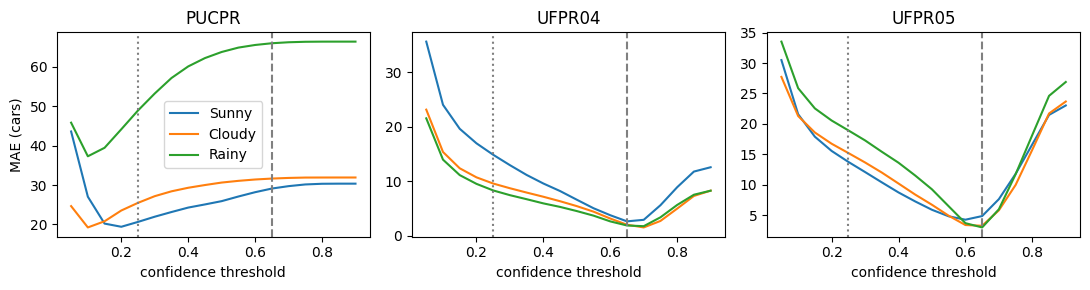

In [25]:
import matplotlib.pyplot as plt
te = out.split != "train"
rows = []
for (lot, w), d in out[te].groupby(["lot", "weather"]):
    e = cnt.loc[d.index].sub(d.n_occupied, axis=0)
    mae = e.abs().mean()
    rows.append(dict(lot=lot, weather=w, imgs=len(d), best_T=mae.idxmin(), min_mae=mae.min(),
                     mae_T025=mae[0.25], mae_T065=mae[0.65], bias_T025=e[0.25].mean()))
S_sens = pd.DataFrame(rows).round(1); print(S_sens.to_string())
S_sens.to_csv("/kaggle/working/sensitivity.csv", index=False)

fig, ax = plt.subplots(1, 3, figsize=(11, 3), sharex=True)
for a, lot in zip(ax, ["PUCPR", "UFPR04", "UFPR05"]):
    for w in ["Sunny", "Cloudy", "Rainy"]:
        d = out[te & (out.lot == lot) & (out.weather == w)]
        if len(d): a.plot(cnt.columns, cnt.loc[d.index].sub(d.n_occupied, axis=0).abs().mean().values, label=w)
    a.axvline(0.25, ls=":", c="gray"); a.axvline(0.65, ls="--", c="gray")
    a.set_title(lot); a.set_xlabel("confidence threshold")
ax[0].set_ylabel("MAE (cars)"); ax[0].legend()
plt.tight_layout(); plt.savefig("/kaggle/working/sensitivity.png", dpi=200)

In [32]:
import glob
print(glob.glob("/kaggle/input/datasets/*"))
print(glob.glob("/kaggle/input/**/worst_frames.csv", recursive=True))

['/kaggle/input/datasets/blanderbuss']
[]


In [33]:
import glob, os, re
import numpy as np, pandas as pd, cv2, xml.etree.ElementTree as ET
from ultralytics import YOLO
det = YOLO("yolo11n.pt")

BASE = "/kaggle/input/datasets/blanderbuss/parking-lot-dataset/PKLot/PKLot"
paths = pd.Series(sorted(glob.glob(f"{BASE}/*/*/*/*.jpg")))
T = paths.str.extract(r"PKLot/PKLot/([^/]+)/([^/]+)/([^/]+)/(\d{4}-\d{2}-\d{2})_(\d{2})_(\d{2})_")
T.columns = ["lot", "weather", "folder", "fdate", "h", "m"]
T["path"] = paths; T["hour"] = T.h.astype(int) + T.m.astype(int) / 60
print(len(T), T.lot.value_counts().to_dict())          # expect 12416

def polys(p):
    return [np.array([[int(pt.get("x")), int(pt.get("y"))] for pt in s.find("contour")], np.int32)
            for s in ET.parse(p[:-4] + ".xml").getroot().findall("space")]
def n_occ(p):
    return sum(s.get("occupied") == "1" for s in ET.parse(p[:-4] + ".xml").getroot().findall("space"))

def audit2(p, save=None):
    im = cv2.imread(p); H, Wd = im.shape[:2]
    mask = np.zeros((H, Wd), np.uint8); cv2.fillPoly(mask, polys(p), 1)
    r = det(p, conf=0.25, imgsz=1280, classes=[2,5,7], device=0, verbose=False)[0]
    xy = r.boxes.xyxy.cpu().numpy().astype(int)
    fr = [mask[max(y1,0):y2, max(x1,0):x2].mean() if y2 > y1 and x2 > x1 else 0 for x1,y1,x2,y2 in xy]
    ins = np.array(fr) >= 0.3
    if save:
        cv2.polylines(im, polys(p), True, (255,0,0), 1)
        for (x1,y1,x2,y2), ok in zip(xy, ins):
            cv2.rectangle(im, (x1,y1), (x2,y2), (0,255,0) if ok else (0,0,255), 2)
        cv2.imwrite(save, im)
    return len(ins), int(ins.sum())

# 1. Overlays: match on the date in the FILENAME and the nearest time
picks = [("UFPR05","2013-04-16",9.0), ("UFPR05","2013-03-20",8.3), ("UFPR05","2013-03-12",12.4),
         ("PUCPR","2012-10-25",19.4), ("PUCPR","2012-10-23",9.0)]
for i, (lot, d, hr) in enumerate(picks):
    c = T[(T.lot == lot) & (T.fdate == d)].assign(dd=lambda x: (x.hour - hr).abs()).nsmallest(1, "dd").iloc[0]
    n, k = audit2(c.path, f"/kaggle/working/overlay_{i}_{lot}_{d}.jpg")
    print(lot, d, round(c.hour, 1), c.weather, "true", n_occ(c.path), "| dets", n, "| in-space", k)

# 2. Confidence inside vs outside the labeled spaces
def conf_split(p):
    im = cv2.imread(p); H, Wd = im.shape[:2]
    mask = np.zeros((H, Wd), np.uint8); cv2.fillPoly(mask, polys(p), 1)
    r = det(p, conf=0.05, imgsz=1280, classes=[2,5,7], device=0, verbose=False)[0]
    xy = r.boxes.xyxy.cpu().numpy().astype(int); c = r.boxes.conf.cpu().numpy()
    fr = np.array([mask[max(y1,0):y2, max(x1,0):x2].mean() if y2 > y1 and x2 > x1 else 0 for x1,y1,x2,y2 in xy])
    return c, fr >= 0.3
for lot in ["UFPR04", "UFPR05", "PUCPR"]:
    s = T[(T.lot == lot) & (T.weather == "Sunny")].sample(20, random_state=1)
    c, ins = map(np.concatenate, zip(*[conf_split(p) for p in s.path]))
    print(lot, "median conf in/out:", round(np.median(c[ins]), 2), round(np.median(c[~ins]), 2),
          "| share >= 0.65 in/out:", round((c[ins] >= .65).mean(), 2), round((c[~ins] >= .65).mean(), 2))

12417 {'PUCPR': 4474, 'UFPR05': 4152, 'UFPR04': 3791}
UFPR05 2013-04-16 9.0 Sunny true 40 | dets 51 | in-space 30
UFPR05 2013-03-20 8.3 Cloudy true 40 | dets 45 | in-space 41
UFPR05 2013-03-12 12.4 Cloudy true 17 | dets 59 | in-space 37
PUCPR 2012-10-25 19.4 Rainy true 100 | dets 18 | in-space 14
PUCPR 2012-10-23 9.0 Rainy true 94 | dets 8 | in-space 7
UFPR04 median conf in/out: 0.65 0.28 | share >= 0.65 in/out: 0.5 0.23
UFPR05 median conf in/out: 0.63 0.49 | share >= 0.65 in/out: 0.46 0.33
PUCPR median conf in/out: 0.18 0.15 | share >= 0.65 in/out: 0.01 0.02


In [34]:
print([p for p in paths if not os.path.exists(p[:-4] + ".xml")])

['/kaggle/input/datasets/blanderbuss/parking-lot-dataset/PKLot/PKLot/PUCPR/Sunny/2012-11-06/2012-11-06_18_48_46.jpg']


In [35]:
d = out[(out.lot == "UFPR05") & (out.day == "2013-03-12")].sort_values("hour")
print(d[["hour", "weather", "n_occupied", "n_det", "n_obb"]].round(1).to_string())

       hour weather  n_occupied  n_det  n_obb
8554    6.2  Cloudy           0    0.0    0.0
8555    6.3  Cloudy           0    0.0    0.0
8556    6.4  Cloudy           0    0.0    0.0
8557    6.5  Cloudy           0    0.0    0.0
8558    6.6  Cloudy           0    0.0    0.0
8559    6.7  Cloudy           0    0.0    0.0
8560    6.8  Cloudy           0    0.0    0.0
8561    6.8  Cloudy           0    0.0    0.0
8562    6.9  Cloudy           4    3.0    0.0
8563    7.0  Cloudy           4    3.0    0.0
8564    7.1  Cloudy           9   10.0    0.0
8565    7.2  Cloudy          12   14.0    0.0
8566    7.2  Cloudy          16   21.0    0.0
8567    7.3  Cloudy          29   36.0    0.0
8568    7.4  Cloudy          38   44.0    0.0
11172   7.5   Sunny          40   56.0    0.0
8569    7.6  Cloudy          40   59.0    0.0
8570    7.7  Cloudy          40   69.0    0.0
8571    7.8  Cloudy          40   70.0    0.0
8572    7.8  Cloudy          40   67.0    0.0
11173   7.9   Sunny          40   

In [37]:
c = T[(T.lot == "UFPR05") & (T.fdate == "2013-03-12")].assign(dd=lambda x: (x.hour - 12.4).abs()).nsmallest(1, "dd").iloc[0]
im = cv2.imread(c.path)
for s in ET.parse(c.path[:-4] + ".xml").getroot().findall("space"):
    pts = np.array([[int(q.get("x")), int(q.get("y"))] for q in s.find("contour")], np.int32)
    cv2.polylines(im, [pts], True, (0, 0, 255) if s.get("occupied") == "1" else (255, 0, 0), 2)
cv2.imwrite("/kaggle/working/occ_check.jpg", im)

True

In [38]:
print(out.groupby("lot").agg(mean_obb=("n_obb", "mean"),
      frac_zero=("n_obb", lambda s: (s == 0).mean())).round(2))
print(out.groupby(["split", "lot"]).n_obb.agg(["mean", "max"]).round(1))

        mean_obb  frac_zero
lot                        
PUCPR      25.45       0.30
UFPR04      0.06       0.96
UFPR05      0.01       0.99
                    mean    max
split       lot                
test_cloudy PUCPR   19.0  136.0
            UFPR04   0.0    3.0
test_newlot UFPR05   0.0    3.0
test_rainy  PUCPR   18.1   95.0
            UFPR04   0.0    4.0
test_sunny  PUCPR   18.1  137.0
            UFPR04   0.0    2.0
train       PUCPR   35.4  164.0
            UFPR04   0.1    6.0


In [39]:
p = out[(out.lot == "PUCPR") & (out.split == "train")]
print("PUCPR train corr with n_occupied:",
      {c: round(p[c].corr(p.n_occupied), 2) for c in ["n_det", "n_obb", "n_seg"]})
u = out[(out.lot == "UFPR04") & (out.split == "train")]
print("UFPR04 train corr with n_occupied:",
      {c: round(u[c].corr(u.n_occupied), 2) for c in ["n_det", "n_obb", "n_seg"]})

PUCPR train corr with n_occupied: {'n_det': np.float64(-0.07), 'n_obb': np.float64(0.49), 'n_seg': np.float64(-0.31)}
UFPR04 train corr with n_occupied: {'n_det': np.float64(0.98), 'n_obb': np.float64(0.13), 'n_seg': np.float64(0.98)}


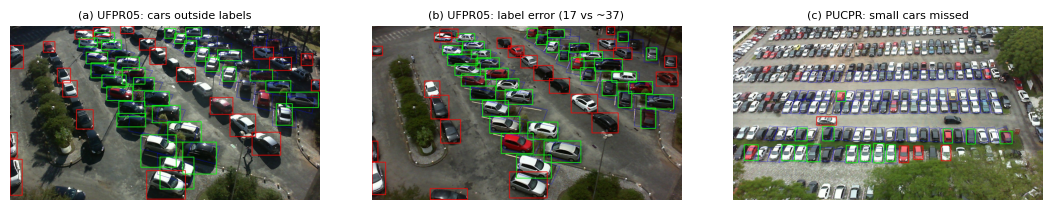

In [40]:
import matplotlib.pyplot as plt, matplotlib.image as mpimg, glob
fs = [sorted(glob.glob(f"/kaggle/working/overlay_{i}_*.jpg"))[0] for i in (0, 2, 3)]
titles = ["(a) UFPR05: cars outside labels", "(b) UFPR05: label error (17 vs ~37)", "(c) PUCPR: small cars missed"]
fig, ax = plt.subplots(1, 3, figsize=(11, 2.1))
for a, f, t in zip(ax, fs, titles):
    a.imshow(mpimg.imread(f)); a.set_title(t, fontsize=8); a.axis("off")
plt.tight_layout(); plt.savefig("/kaggle/working/audit_panel.pdf", dpi=200, bbox_inches="tight")

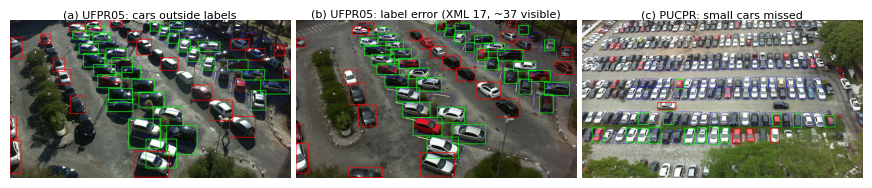

In [41]:
fig, ax = plt.subplots(1, 3, figsize=(11, 2.6), gridspec_kw=dict(wspace=0.02))
titles = ["(a) UFPR05: cars outside labels", "(b) UFPR05: label error (XML 17, ~37 visible)",
          "(c) PUCPR: small cars missed"]
for a, f, t in zip(ax, fs, titles):
    a.imshow(mpimg.imread(f)); a.set_title(t, fontsize=8, pad=2); a.axis("off")
plt.savefig("/kaggle/working/audit_panel.pdf", bbox_inches="tight", pad_inches=0.02)

In [42]:
import os
for f in ["audit_panel.pdf", "sensitivity.png", "sensitivity.pdf"]:
    print(f, os.path.exists(f"/kaggle/working/{f}"))

audit_panel.pdf True
sensitivity.png True
sensitivity.pdf False
